# Qwen 2.5 7B Zero-Shot Paraphrase Identification (Hugging Face, bf16)
Qwen 2.5 7B Instruct is loaded directly with Hugging Face on an A100 and scored on the full MRPC (408), QQP (5,000) and PAWS (8,000) test sets. The label is chosen from the model's probability for "paraphrase" versus "not_paraphrase", which gives a score (`qwen_logit_prob`) as well as a label. Results are compared with the earlier Ollama (4-bit) run.

## 1. Check the Session Hardware
GPU, CPUs, memory and the precision to use (bfloat16 on an A100).

In [2]:
import os, subprocess, torch

print("Node        :", subprocess.getoutput("hostname"))
print("GPU         :", subprocess.getoutput("nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader"))
print("CPUs given  :", len(os.sched_getaffinity(0)))
print("RAM given MB:", os.environ.get("SLURM_MEM_PER_NODE", "not set (see line below)"))
print(subprocess.getoutput("free -g | head -2"))
print("Time left   :", subprocess.getoutput("squeue -h -j $SLURM_JOB_ID -o %L"))

if torch.cuda.is_available():
    cc = torch.cuda.get_device_capability()
    print("Compute cap :", cc, "->", "use bfloat16" if cc >= (8, 0) else "use float16 (no bf16)")
else:
    print("NO GPU visible to torch")

Node        : d1029
GPU         : NVIDIA A100-SXM4-80GB, 81920 MiB, 570.86.15
CPUs given  : 8
RAM given MB: 32768
               total        used        free      shared  buff/cache   available
Mem:             502          31          90          11         381         457
Time left   : /bin/sh: 1: squeue: not found
Compute cap : (8, 0) -> use bfloat16


## 2. Install Packages

In [3]:
%pip install -q -U transformers accelerate

ERROR: Could not install packages due to an OSError: [Errno 30] Read-only file system: '/opt/miniconda/envs/eai/lib/python3.10/site-packages/typing_extensions.py'


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import os, numpy as np, pandas as pd
import time, torch
from transformers import AutoTokenizer, AutoModelForCausalLM
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.lines import Line2D
from sklearn.metrics import accuracy_score, f1_score, roc_curve, roc_auc_score, confusion_matrix


/home/bhandari.ru/.local/lib/python3.10/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (7.4.0.post1)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(


## 3. Load Qwen 2.5 7B Instruct (bf16)
Downloads the weights to the scratch cache the first time, then loads them onto the GPU.

In [4]:
os.environ["HF_HOME"] = "/scratch/bhandari.ru/hf_cache"
MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"
t0 = time.time()
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.bfloat16, device_map="cuda").eval()
print("loaded in", round(time.time() - t0), "s | GPU GB used:", round(torch.cuda.memory_allocated() / 1e9, 1))

/home/bhandari.ru/.local/lib/python3.10/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (7.4.0.post1)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

... (6 outputs left out)

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

loaded in 144 s | GPU GB used: 15.3


## 4. Prompt and Probability Scoring
The same instruction prompt as the Ollama run. Instead of generating text, the model is read at the point where it would start the label, and the probabilities for "paraphrase" and "not_paraphrase" are renormalized to give `qwen_logit_prob`.

In [5]:

SYSTEM = (
    "You are a paraphrase detector. Given two sentences, decide whether they "
    "express the same meaning. Answer 'paraphrase' only if all key facts and "
    "relations are preserved; otherwise 'not_paraphrase'. "
    'Respond only with valid JSON: {"label": "paraphrase"} or {"label": "not_paraphrase"}.'
)
PREFILL = '{"label": "'     # we stop here and read the model's next-token choice

def build(s1, s2):
    msgs = [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"Sentence 1: {s1}\nSentence 2: {s2}"}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True) + PREFILL

def first_new_token(cand):
    base = tok(build("a", "b"), add_special_tokens=False).input_ids
    full = tok(build("a", "b") + cand, add_special_tokens=False).input_ids
    assert full[:len(base)] == base, "tokenization merged across the prefill boundary"
    return full[len(base)]

ID_PARA, ID_NOT = first_new_token("paraphrase"), first_new_token("not_paraphrase")
print(repr(tok.decode([ID_PARA])), "|", repr(tok.decode([ID_NOT])))
assert ID_PARA != ID_NOT

@torch.no_grad()
def score(s1_list, s2_list, bs=32):
    out = []
    for i in range(0, len(s1_list), bs):
        texts = [build(a, b) for a, b in zip(s1_list[i:i+bs], s2_list[i:i+bs])]
        enc = tok(texts, return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        logits = model(**enc).logits[:, -1, :].float()
        two = torch.stack([logits[:, ID_NOT], logits[:, ID_PARA]], dim=1)
        out.extend(torch.softmax(two, dim=1)[:, 1].cpu().tolist())   # P("paraphrase") vs "not_paraphrase"
    return out

'par' | 'not'


## 5. Dataset Runner with Checkpointing
Scores a full test set in batches, saves progress every 640 rows, resumes if interrupted, and writes the results CSV.

In [6]:
OUT_DIR = "qwen_hf_results"; os.makedirs(OUT_DIR, exist_ok=True)

def run_dataset(name, expected_rows, limit=None, bs=32, chunk=640):
    df = pd.read_csv(f"splits/{name}_test.csv")
    assert len(df) == expected_rows
    use_ckpt = limit is None
    if limit: df = df.iloc[:limit].copy()
    partial = f"{OUT_DIR}/{name}_partial.csv"
    probs = pd.read_csv(partial)["qwen_logit_prob"].tolist() if (use_ckpt and os.path.exists(partial)) else []
    print(f"{name}: {len(df)} rows, resuming from {len(probs)}")
    for i in range(len(probs), len(df), chunk):
        j = min(i + chunk, len(df))
        probs += score(df.sentence1[i:j].tolist(), df.sentence2[i:j].tolist(), bs)
        if use_ckpt: pd.DataFrame({"qwen_logit_prob": probs}).to_csv(partial, index=False)
        print(f"  {j}/{len(df)}")
    df["qwen_logit_prob"] = probs
    df["pred"] = (df["qwen_logit_prob"] >= 0.5).astype(int)
    if use_ckpt: df.to_csv(f"{OUT_DIR}/qwen_hf_{name}_results.csv", index=False)
    return df

## 7. Full Runs: MRPC, QQP and PAWS

In [8]:
mrpc = run_dataset("mrpc", 408)
qqp  = run_dataset("qqp", 5000)
paws = run_dataset("paws", 8000)

mrpc: 408 rows, resuming from 0
  408/408
qqp: 5000 rows, resuming from 0
  640/5000
  1280/5000
  1920/5000
  2560/5000
  3200/5000
  3840/5000
  4480/5000
  5000/5000
paws: 8000 rows, resuming from 0
  640/8000
  1280/8000
  1920/8000
  2560/8000
  3200/8000
  3840/8000
  4480/8000
  5120/8000
  5760/8000
  6400/8000
  7040/8000
  7680/8000
  8000/8000


## 8. Results Summary
Accuracy, F1, AUC, the share of probabilities that are extreme (below 0.05 or above 0.95), and the label agreement with the Ollama run.

In [9]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

rows = []
for n, d in [("MRPC", mrpc), ("QQP", qqp), ("PAWS", paws)]:
    p = d["qwen_logit_prob"]
    rows.append({"Dataset": n, "n": len(d),
                 "Accuracy": round(accuracy_score(d.label, d.pred), 4),
                 "F1": round(f1_score(d.label, d.pred), 4),
                 "AUC": round(roc_auc_score(d.label, p), 4),
                 "% prob<0.05 or >0.95": round(((p < 0.05) | (p > 0.95)).mean() * 100, 1)})
    old = f"qwen_results/qwen_{n.lower()}_results.csv"
    if os.path.exists(old):
        rows[-1]["agree_with_Ollama_%"] = round((pd.read_csv(old).qwen_pred.values == d.pred.values).mean() * 100, 1)
summary = pd.DataFrame(rows); summary.to_csv(f"{OUT_DIR}/qwen_hf_summary.csv", index=False)
print(summary.to_string(index=False))

Dataset    n  Accuracy     F1    AUC  % prob<0.05 or >0.95  agree_with_Ollama_%
   MRPC  408    0.7770 0.8273 0.8270                  92.4                 94.4
    QQP 5000    0.8120 0.6950 0.9021                  95.8                 97.3
   PAWS 8000    0.8484 0.8402 0.9132                  96.0                 97.2


In [7]:
FIG = "qwen_hf_results/figures"; os.makedirs(FIG, exist_ok=True)
names = ["mrpc", "qqp", "paws"]
LAB = {"mrpc": "MRPC", "qqp": "QQP", "paws": "PAWS"}
COL = {"mrpc": "#d95f02", "qqp": "#7570b3", "paws": "#1b9e77"}
C_OLL, C_HF = "#f0a04b", "#3b75af"
NOTE = "Ollama = 4-bit, generated label | HF = bf16, probability label"


In [8]:
#load both runs and check they line up row by row 
Y, PO, PH, PR = {}, {}, {}, {}
for n in names:
    o = pd.read_csv(f"qwen_results/qwen_{n}_results.csv")
    h = pd.read_csv(f"qwen_hf_results/qwen_hf_{n}_results.csv")
    assert len(o) == len(h), f"{n}: row counts differ"
    assert (o.sentence1.values == h.sentence1.values).all() and (o.label.values == h.label.values).all(), f"{n}: rows not aligned"
    assert (o.qwen_pred != -1).all(), f"{n}: Ollama run has failed rows"
    Y[n], PO[n], PH[n], PR[n] = h.label.values, o.qwen_pred.values, h.pred.values, h.qwen_logit_prob.values
maj = {n: max(Y[n].mean(), 1 - Y[n].mean()) for n in names}


## 9. Comparison of the Two Runs (Figures 1 to 5)
Accuracy and F1, confusion matrices, ROC curves, the score distribution with a reliability diagram, and a disagreement analysis, for Ollama (4-bit, generated label) and HF (bf16, probability label).

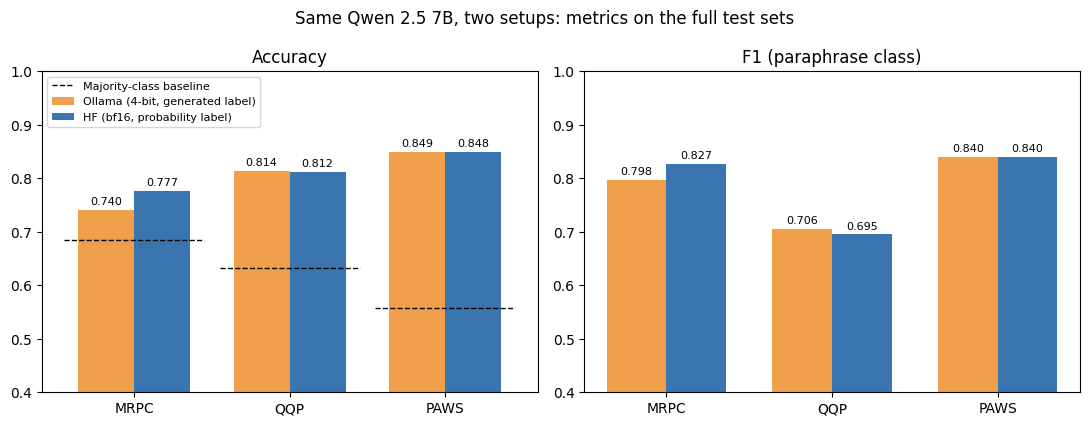

In [9]:
x = np.arange(3); w = 0.36
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for a, (title, fn) in zip(ax, [("Accuracy", accuracy_score), ("F1 (paraphrase class)", f1_score)]):
    vo = [fn(Y[n], PO[n]) for n in names]; vh = [fn(Y[n], PH[n]) for n in names]
    a.bar(x - w/2, vo, w, label="Ollama (4-bit, generated label)", color=C_OLL)
    a.bar(x + w/2, vh, w, label="HF (bf16, probability label)", color=C_HF)
    for xs, vals in [(x - w/2, vo), (x + w/2, vh)]:
        for xi, v in zip(xs, vals): a.text(xi, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
    if title == "Accuracy":
        for xi, n in zip(x, names): a.hlines(maj[n], xi - 0.45, xi + 0.45, colors="k", linestyles="--", lw=1)
        a.plot([], [], "k--", lw=1, label="Majority-class baseline")
    a.set_xticks(x); a.set_xticklabels([LAB[n] for n in names]); a.set_ylim(0.4, 1.0); a.set_title(title)
ax[0].legend(fontsize=8, loc="upper left")
plt.suptitle("Same Qwen 2.5 7B, two setups: metrics on the full test sets")
plt.tight_layout(); plt.savefig(f"{FIG}/1_runs_metrics.png", dpi=200); plt.show()


### Figure 1: Accuracy and F1, Ollama (4-bit) vs HF (bf16)
**What it shows:** Accuracy and F1 on the full test sets for the same Qwen 2.5 7B run two ways: Ollama (4-bit weights, label generated as text) and Hugging Face (bf16 weights, label chosen from the model's probability). The dashed lines mark the majority-class baseline.

**Findings:** QQP and PAWS are essentially unchanged (QQP 0.814 vs 0.812, PAWS 0.849 vs 0.848). MRPC rises from 0.740 to 0.777 accuracy and from 0.798 to 0.827 F1, but it has only 408 test pairs, so this gap is within what a few pairs can cause. Both runs beat the majority baseline on every dataset.

**Meaning:** The two setups give the same picture of Qwen's ability, so the conclusions do not depend on how it was served.

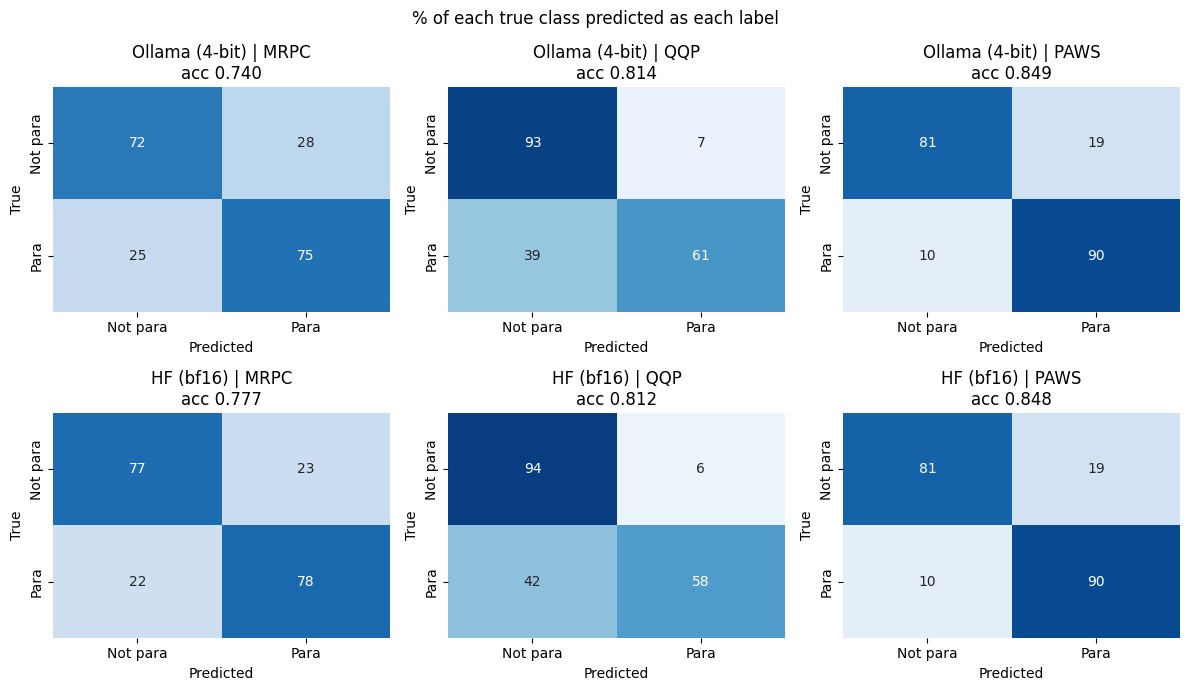

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for r, (rname, P) in enumerate([("Ollama (4-bit)", PO), ("HF (bf16)", PH)]):
    for c, n in enumerate(names):
        cm = confusion_matrix(Y[n], P[n], normalize="true") * 100
        sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax[r, c],
                    xticklabels=["Not para", "Para"], yticklabels=["Not para", "Para"])
        ax[r, c].set_title(f"{rname} | {LAB[n]}\nacc {accuracy_score(Y[n], P[n]):.3f}")
        ax[r, c].set_xlabel("Predicted"); ax[r, c].set_ylabel("True")
plt.suptitle("% of each true class predicted as each label")
plt.tight_layout(); plt.savefig(f"{FIG}/2_runs_confusion.png", dpi=200); plt.show()


### Figure 2: Confusion Matrices (% of each true class)
**What it shows:** For each run and dataset, the share of true non-paraphrases and true paraphrases that Qwen labeled each way.

**Findings:** The error pattern depends on the dataset and stays the same across runs. On QQP, Qwen misses paraphrases (39-42% of true paraphrases are called not-paraphrase) but rarely raises false alarms (6-7%). On PAWS it does the opposite, with 19% false alarms and only 10% misses. MRPC errors are balanced (about 22-28% each way).

**Meaning:** Qwen's weakness is dataset-specific. On informal QQP questions it is too strict, and on PAWS, where wrong pairs share almost all their words, it is too lenient. This is a property of the model and the task, not of the serving method.

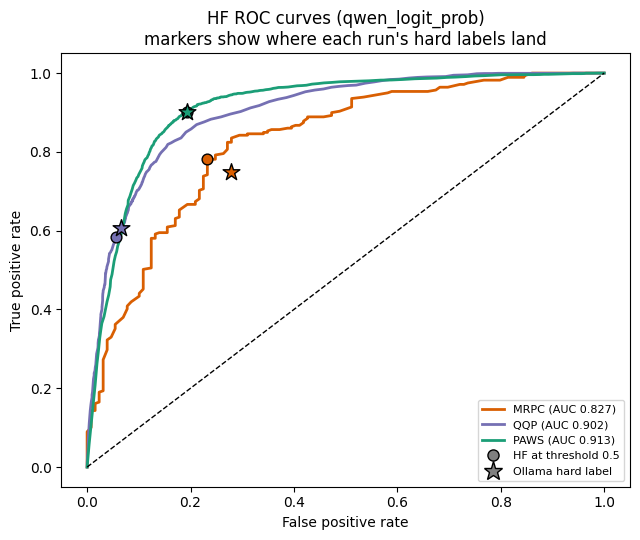

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for n in names:
    fpr, tpr, _ = roc_curve(Y[n], PR[n])
    ax.plot(fpr, tpr, color=COL[n], lw=2, label=f"{LAB[n]} (AUC {roc_auc_score(Y[n], PR[n]):.3f})")
    for P, mk in [(PH[n], "o"), (PO[n], "*")]:
        tn, fp, fn, tp = confusion_matrix(Y[n], P).ravel()
        ax.scatter(fp / (fp + tn), tp / (tp + fn), marker=mk, s=160 if mk == "*" else 60,
                   color=COL[n], edgecolor="k", zorder=5)
ax.plot([0, 1], [0, 1], "k--", lw=1)
handles, _ = ax.get_legend_handles_labels()
handles += [Line2D([], [], marker="o", color="w", markerfacecolor="grey", markeredgecolor="k", markersize=8, label="HF at threshold 0.5"),
            Line2D([], [], marker="*", color="w", markerfacecolor="grey", markeredgecolor="k", markersize=14, label="Ollama hard label")]
ax.legend(handles=handles, fontsize=8, loc="lower right")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("HF ROC curves (qwen_logit_prob)\nmarkers show where each run's hard labels land")
plt.tight_layout(); plt.savefig(f"{FIG}/3_hf_roc.png", dpi=200); plt.show()


### Figure 3: ROC Curves for `qwen_logit_prob` (HF run)
**What it shows:** How well Qwen's probability separates true paraphrases from non-paraphrases at every possible cutoff. Circles mark the HF run's 0.5 cutoff, and stars mark the Ollama hard labels.

**Findings:** AUC is 0.913 on PAWS, 0.902 on QQP and 0.827 on MRPC. All curves are far above the diagonal (a coin flip, AUC 0.5). On QQP and PAWS, the HF and Ollama markers sit almost on top of each other. On MRPC they are slightly apart.

**Meaning:** Qwen's probability ranks pairs well, especially on PAWS and QQP. On QQP, the curve shows that a cutoff below 0.5 would find more paraphrases at a small cost in false alarms, since the 0.5 point sits where the curve is still rising steeply.

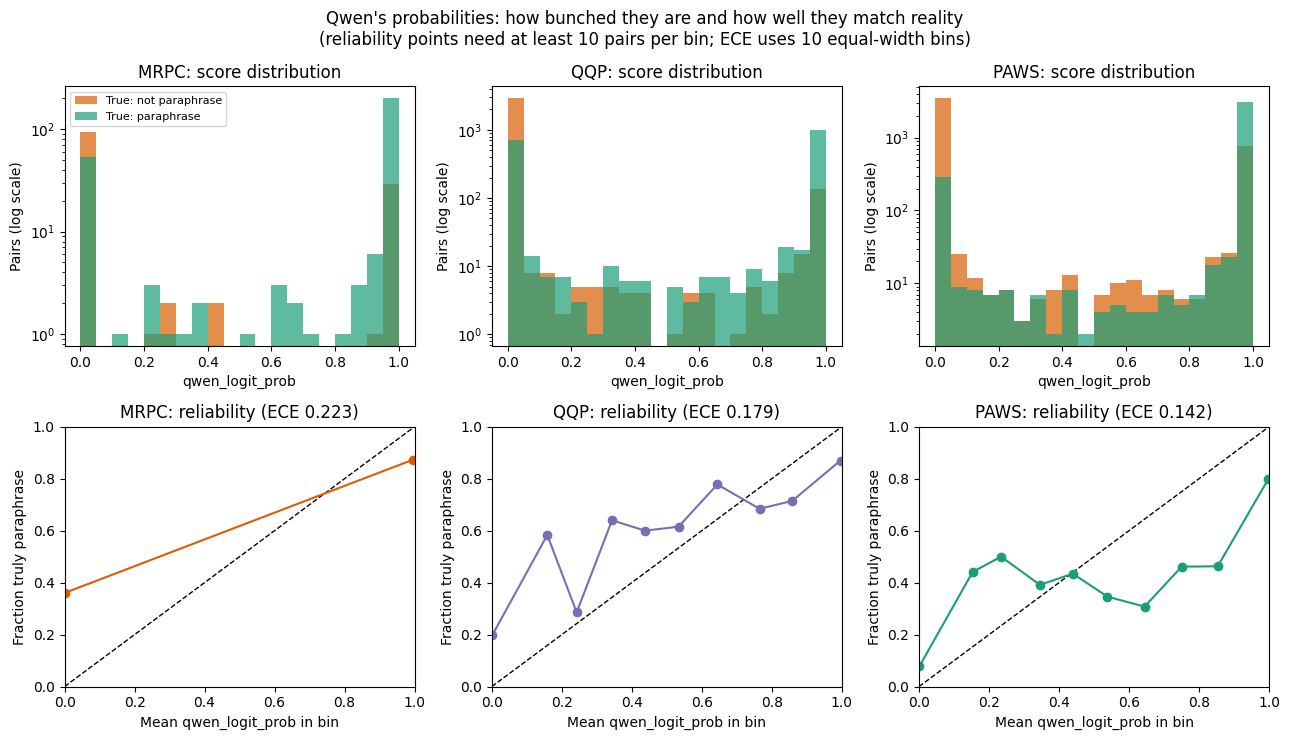

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(13, 7.5))
edges = np.linspace(0, 1, 11)
for c, n in enumerate(names):
    p, y = PR[n], Y[n]
    a = ax[0, c]
    a.hist(p[y == 0], bins=np.linspace(0, 1, 21), alpha=0.7, color="#d95f02", label="True: not paraphrase", log=True)
    a.hist(p[y == 1], bins=np.linspace(0, 1, 21), alpha=0.7, color="#1b9e77", label="True: paraphrase", log=True)
    a.set_title(f"{LAB[n]}: score distribution"); a.set_xlabel("qwen_logit_prob"); a.set_ylabel("Pairs (log scale)")
    if c == 0: a.legend(fontsize=8)
    b = ax[1, c]
    idx = np.clip(np.digitize(p, edges) - 1, 0, 9)
    ece, xs, ys = 0.0, [], []
    for k in range(10):
        m = idx == k
        if m.sum() == 0: continue
        conf, frac = p[m].mean(), y[m].mean()
        ece += m.sum() / len(p) * abs(frac - conf)
        if m.sum() >= 10: xs.append(conf); ys.append(frac)
    b.plot([0, 1], [0, 1], "k--", lw=1); b.plot(xs, ys, marker="o", color=COL[n])
    b.set_title(f"{LAB[n]}: reliability (ECE {ece:.3f})")
    b.set_xlabel("Mean qwen_logit_prob in bin"); b.set_ylabel("Fraction truly paraphrase")
    b.set_xlim(0, 1); b.set_ylim(0, 1)
plt.suptitle("Qwen's probabilities: how bunched they are and how well they match reality\n(reliability points need at least 10 pairs per bin; ECE uses 10 equal-width bins)")
plt.tight_layout(); plt.savefig(f"{FIG}/4_hf_prob_distribution_reliability.png", dpi=200); plt.show()


### Figure 4: Score Distribution and Reliability Diagram
**What it shows:** Top: a log-scale histogram of `qwen_logit_prob` split by true label. Bottom: a reliability diagram, plotting the mean predicted probability in each bin against the fraction of pairs that are truly paraphrases. A perfectly calibrated model follows the diagonal. ECE summarizes the gap.

**Findings:** Scores are strongly bunched at the extremes: 92-96% fall below 0.05 or above 0.95. The distribution is U-shaped, with very few pairs in the middle. ECE is 0.223 (MRPC), 0.179 (QQP) and 0.142 (PAWS). In the extreme bins, there are still hundreds of mistakes, so a score near 0 or 1 does not guarantee a correct label. The MRPC reliability plot has only two points with enough pairs, so it is not informative.

**Meaning:** Qwen is overconfident. Its probabilities act almost like hard labels, which is unlike a trained encoder's scores, so `qwen_logit_prob` should not be read as a calibrated "chance of being a paraphrase". It is useful for ranking (Figure 3), not as a trustworthy confidence value.

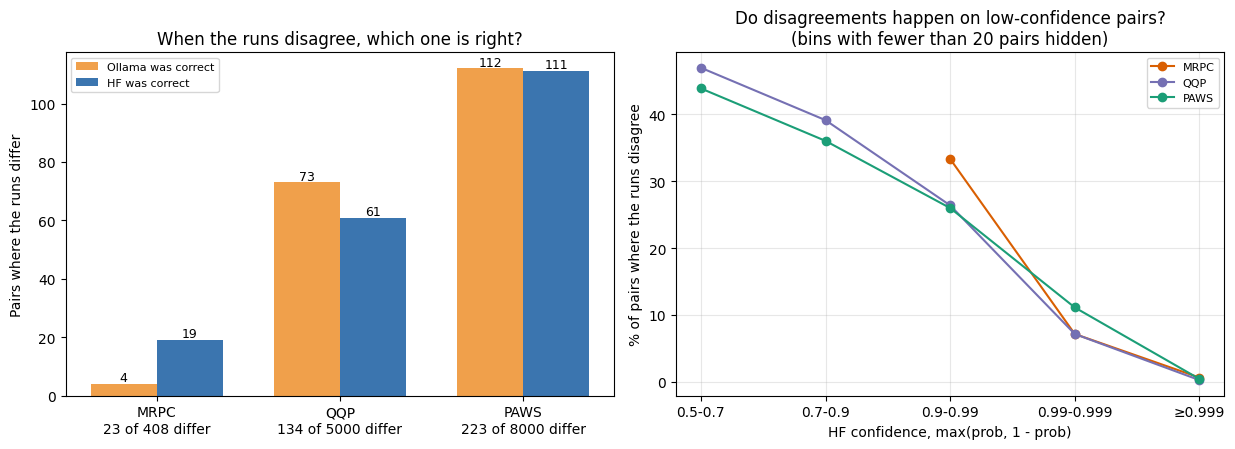

['1_runs_metrics.png', '2_runs_confusion.png', '3_hf_roc.png', '4_hf_prob_distribution_reliability.png', '5_run_disagreement.png', '6_hf_precision_recall.png', '7_hf_coverage_accuracy.png', '8_hf_accuracy_by_overlap_length.png', '9_hf_threshold_sensitivity.png']


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
ol_ok, hf_ok, tick = [], [], []
for n in names:
    d = PO[n] != PH[n]
    ol_ok.append(int((PO[n][d] == Y[n][d]).sum())); hf_ok.append(int((PH[n][d] == Y[n][d]).sum()))
    tick.append(f"{LAB[n]}\n{int(d.sum())} of {len(Y[n])} differ")
a = ax[0]
a.bar(x - w/2, ol_ok, w, color=C_OLL, label="Ollama was correct")
a.bar(x + w/2, hf_ok, w, color=C_HF, label="HF was correct")
for xs, vals in [(x - w/2, ol_ok), (x + w/2, hf_ok)]:
    for xi, v in zip(xs, vals): a.text(xi, v + 1, str(v), ha="center", fontsize=9)
a.set_xticks(x); a.set_xticklabels(tick); a.set_ylabel("Pairs where the runs differ")
a.set_title("When the runs disagree, which one is right?"); a.legend(fontsize=8)

cb = [0.5, 0.7, 0.9, 0.99, 0.999, 1.0001]; cl = ["0.5-0.7", "0.7-0.9", "0.9-0.99", "0.99-0.999", "≥0.999"]
for n in names:
    conf = np.maximum(PR[n], 1 - PR[n])
    tmp = pd.DataFrame({"bin": pd.cut(conf, cb, labels=cl, include_lowest=True), "dis": PO[n] != PH[n]})
    g = tmp.groupby("bin", observed=False).dis
    rate = (g.mean() * 100).where(g.size() >= 20)
    ax[1].plot(cl, rate.values, marker="o", color=COL[n], label=LAB[n])
ax[1].set_xlabel("HF confidence, max(prob, 1 - prob)"); ax[1].set_ylabel("% of pairs where the runs disagree")
ax[1].set_title("Do disagreements happen on low-confidence pairs?\n(bins with fewer than 20 pairs hidden)")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIG}/5_run_disagreement.png", dpi=200); plt.show()

print(sorted(os.listdir(FIG)))

### Figure 5: Where the Two Runs Disagree
**What it shows:** Left: among the pairs where Ollama and HF give different labels, how many each run gets right. Right: how often the runs disagree as a function of HF's confidence.

**Findings:** The runs disagree on only 23 of 408 (MRPC), 134 of 5,000 (QQP) and 223 of 8,000 (PAWS) pairs, which is 2.7-5.6% of each set. On QQP and PAWS, neither run is clearly better when they disagree (73 vs 61 on QQP, 112 vs 111 on PAWS). On MRPC, HF is right more often (19 vs 4). The disagreement rate drops steeply as HF's confidence rises, from roughly 40-47% in the least confident bin to below 1% above 0.999.

**Meaning:** Differences between the setups come almost entirely from borderline pairs where Qwen was nearly undecided. Where the model is confident, 4-bit compression and the label rule make no difference.

## 10. HF Run Analysis (Figures 6 to 9)
Precision-recall curves, accuracy as coverage grows, accuracy by word overlap and sentence length, and sensitivity to the decision threshold. These use the HF run only.

In [14]:
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score, precision_score, recall_score, accuracy_score, f1_score

FIG = "qwen_hf_results/figures"; os.makedirs(FIG, exist_ok=True)
names = ["mrpc", "qqp", "paws"]; LAB = {"mrpc": "MRPC", "qqp": "QQP", "paws": "PAWS"}
COL = {"mrpc": "#d95f02", "qqp": "#7570b3", "paws": "#1b9e77"}
D = {n: pd.read_csv(f"qwen_hf_results/qwen_hf_{n}_results.csv") for n in names}


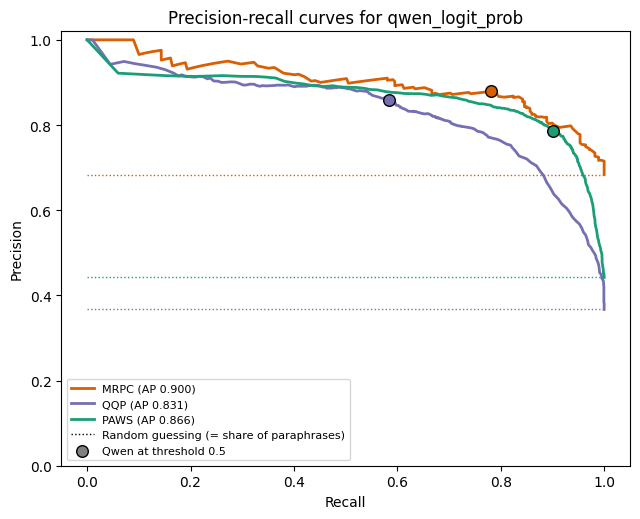

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 5.3))
for n in names:
    d = D[n]; pr, rc, _ = precision_recall_curve(d.label, d.qwen_logit_prob)
    ap = average_precision_score(d.label, d.qwen_logit_prob)
    ax.plot(rc, pr, color=COL[n], lw=2, label=f"{LAB[n]} (AP {ap:.3f})")
    ax.hlines(d.label.mean(), 0, 1, colors=COL[n], linestyles=":", lw=1)
    ax.scatter(recall_score(d.label, d.pred), precision_score(d.label, d.pred), color=COL[n], edgecolor="k", s=70, zorder=5)
ax.plot([], [], "k:", lw=1, label="Random guessing (= share of paraphrases)")
ax.scatter([], [], color="grey", edgecolor="k", s=70, label="Qwen at threshold 0.5")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1.02); ax.legend(fontsize=8, loc="lower left")
ax.set_title("Precision-recall curves for qwen_logit_prob")
plt.tight_layout(); plt.savefig(f"{FIG}/6_hf_precision_recall.png", dpi=200); plt.show()


### Figure 6: Precision-Recall Curves for `qwen_logit_prob`
**What it shows:** The trade-off between precision (how many of Qwen's "paraphrase" calls are right) and recall (how many true paraphrases it finds), across every possible cutoff. Dotted lines show what random guessing would score, which equals the share of paraphrases in each test set. Circles mark the 0.5 cutoff used in the run.

**Findings:** Average precision (AP) is 0.900 on MRPC, 0.866 on PAWS and 0.831 on QQP. All three are far above random guessing (about 0.68, 0.44 and 0.37). At the 0.5 cutoff, Qwen reaches about 0.88 precision and 0.78 recall on MRPC, about 0.79 and 0.90 on PAWS, and about 0.86 and 0.58 on QQP. On QQP and PAWS, precision falls steeply once recall passes about 0.8-0.9.

**Meaning:** Qwen's score separates paraphrases from non-paraphrases well on all three datasets. The 0.5 cutoff is cautious on QQP, since it gives high precision but finds only about 58% of the paraphrases. Pushing recall toward 100% on QQP or PAWS would cost a lot of precision.

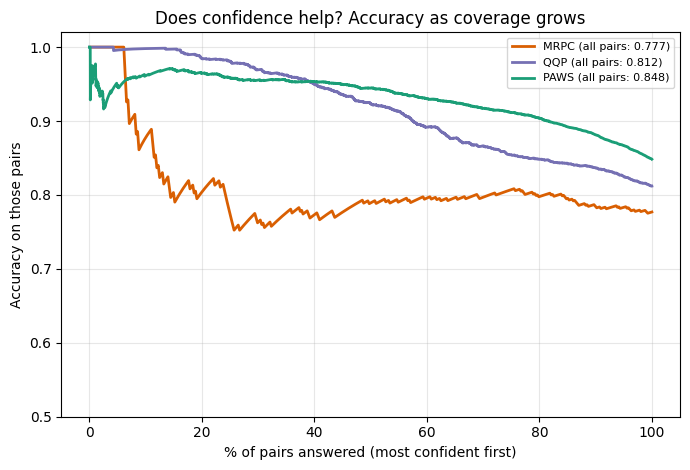

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.8))
for n in names:
    d = D[n]; conf = np.maximum(d.qwen_logit_prob, 1 - d.qwen_logit_prob).values
    ok = (d.label.values == d.pred.values)[np.argsort(-conf, kind="stable")]
    cov = np.arange(1, len(ok) + 1) / len(ok); acc = np.cumsum(ok) / np.arange(1, len(ok) + 1)
    ax.plot(cov * 100, acc, color=COL[n], lw=2, label=f"{LAB[n]} (all pairs: {ok.mean():.3f})")
ax.set_xlabel("% of pairs answered (most confident first)"); ax.set_ylabel("Accuracy on those pairs")
ax.set_title("Does confidence help? Accuracy as coverage grows"); ax.set_ylim(0.5, 1.02); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/7_hf_coverage_accuracy.png", dpi=200); plt.show()


### Figure 7: Accuracy as Coverage Grows (Most Confident Pairs First)
**What it shows:** Pairs are sorted from Qwen's most to least confident, and the curve shows accuracy on the top X% of them. The right end of each curve is the overall accuracy on the full test set.

**Findings:** Confidence is a useful signal on QQP and PAWS. QQP accuracy is close to 1.0 on the most confident pairs and stays above about 0.95 for roughly the top 40%, then declines to 0.812. PAWS stays around 0.96-0.97 for the top 40% and declines to 0.848. On MRPC the pattern is much weaker: accuracy is perfect only for the top few percent, then drops to about 0.75-0.80 and stays there. MRPC has only 408 test pairs, so its curve is noisy.

**Meaning:** On QQP and PAWS, an application could trust Qwen on its confident answers and send the rest for review, which would raise accuracy well above the overall figure. On MRPC, confidence does not help much. Since most scores sit near 0 or 1 (Figure 4), the ordering inside the top group rests on very small differences.

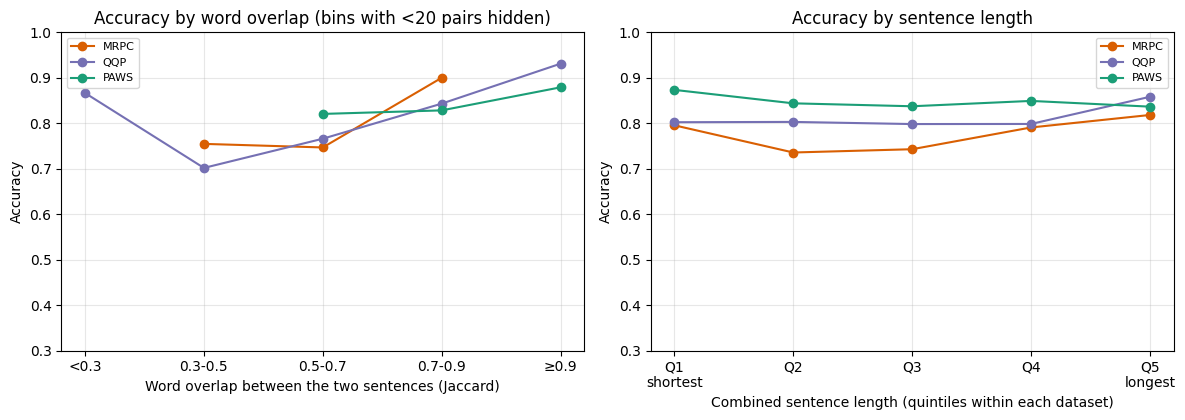

In [17]:
jac = lambda a, b: len(set(str(a).lower().split()) & set(str(b).lower().split())) / max(len(set(str(a).lower().split()) | set(str(b).lower().split())), 1)
ob = [0, .3, .5, .7, .9, 1.0001]; ol = ["<0.3", "0.3-0.5", "0.5-0.7", "0.7-0.9", "≥0.9"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for n in names:
    d = D[n].copy()
    d["ok"] = (d.label == d.pred).astype(int)
    d["ov"] = pd.cut([jac(a, b) for a, b in zip(d.sentence1, d.sentence2)], ob, labels=ol, include_lowest=True)
    g = d.groupby("ov", observed=False).ok; ax[0].plot(ol, g.mean().where(g.size() >= 20), marker="o", color=COL[n], label=LAB[n])
    d["len"] = d.sentence1.str.split().str.len() + d.sentence2.str.split().str.len()
    d["lq"] = pd.qcut(d["len"], 5, labels=["Q1\nshortest", "Q2", "Q3", "Q4", "Q5\nlongest"], duplicates="drop")
    g = d.groupby("lq", observed=False).ok; ax[1].plot(g.mean().index.astype(str), g.mean(), marker="o", color=COL[n], label=LAB[n])
ax[0].set_xlabel("Word overlap between the two sentences (Jaccard)"); ax[0].set_title("Accuracy by word overlap (bins with <20 pairs hidden)")
ax[1].set_xlabel("Combined sentence length (quintiles within each dataset)"); ax[1].set_title("Accuracy by sentence length")
for a in ax: a.set_ylabel("Accuracy"); a.set_ylim(0.3, 1.0); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/8_hf_accuracy_by_overlap_length.png", dpi=200); plt.show()


### Figure 8: Accuracy by Word Overlap and Sentence Length
**What it shows:** Left: accuracy grouped by how many words the two sentences share (Jaccard overlap). Bins with fewer than 20 pairs are hidden. Right: accuracy grouped by combined sentence length, in five equal-sized groups within each dataset.

**Findings:** Accuracy generally rises with word overlap: on QQP it goes from about 0.70 at 0.3-0.5 overlap to about 0.93 at 0.9 or more, with a high value (about 0.87) for pairs sharing almost no words. On PAWS, accuracy is about 0.82 at 0.5-0.7 overlap and about 0.88 at 0.9 or more. Almost all PAWS pairs are in the high-overlap bins, so its lower-overlap bins are hidden. Length has little effect. PAWS stays around 0.84-0.87 and QQP around 0.80-0.86 across all five groups. MRPC varies more (about 0.74-0.82), but each of its groups has only about 80 pairs.

**Meaning:** Qwen is not mainly confused by long sentences. The overlap result is partly a label-mix effect: in QQP and MRPC, high-overlap pairs are mostly true paraphrases, so higher accuracy there does not by itself show better reasoning. The mid-overlap QQP pairs are the hardest, since they look related but are often not the same question.

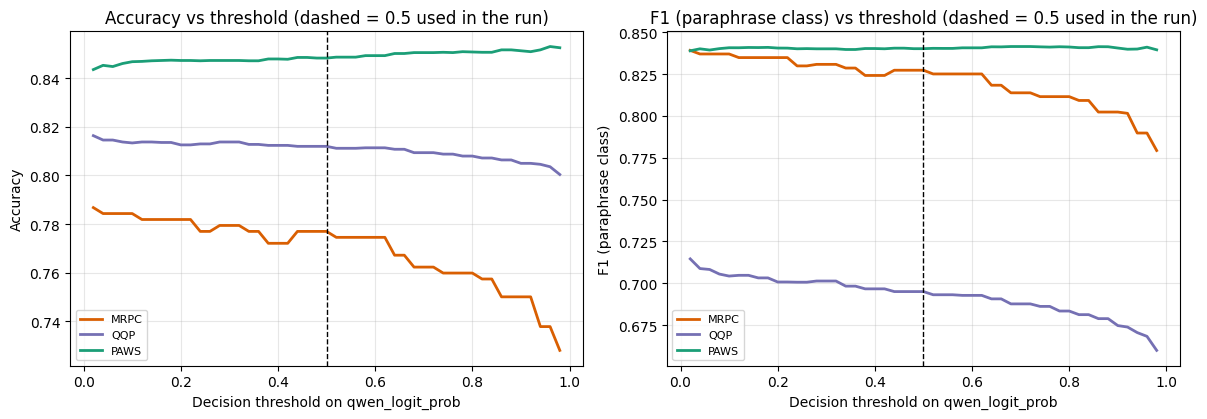

In [18]:
ths = np.linspace(0.02, 0.98, 49)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for n in names:
    d = D[n]; P = [(d.qwen_logit_prob.values >= t).astype(int) for t in ths]
    ax[0].plot(ths, [accuracy_score(d.label, p) for p in P], color=COL[n], lw=2, label=LAB[n])
    ax[1].plot(ths, [f1_score(d.label, p) for p in P], color=COL[n], lw=2, label=LAB[n])
for a, t in zip(ax, ["Accuracy", "F1 (paraphrase class)"]):
    a.axvline(0.5, color="k", ls="--", lw=1); a.set_xlabel("Decision threshold on qwen_logit_prob"); a.set_ylabel(t)
    a.set_title(f"{t} vs threshold (dashed = 0.5 used in the run)"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/9_hf_threshold_sensitivity.png", dpi=200); plt.show()


### Figure 9: Sensitivity to the Decision Threshold
**What it shows:** Accuracy and F1 as the cutoff on `qwen_logit_prob` moves from 0.02 to 0.98. The dashed line marks the 0.5 cutoff used in the run.

**Findings:** The curves are nearly flat. PAWS accuracy stays between about 0.844 and 0.853 and its F1 stays near 0.84 across the whole range. QQP accuracy moves by about 1.5 points and MRPC by up to 6 points, with the largest drops at very high thresholds (above about 0.9). Lower thresholds are slightly better on MRPC and QQP, where Qwen tends to under-call paraphrases, but the gain over 0.5 is small (roughly 1 point).

**Meaning:** Because the scores are bunched near 0 and 1 (Figure 4), moving the cutoff changes the label of very few pairs, so the results do not depend on the 0.5 choice. This was checked on the test set for illustration only. A tuned threshold should be chosen on the dev split and applied once to test, or it would give Qwen an advantage over the encoders.

## 11. Most Confident Mistakes
The pairs where Qwen was most confident and still disagreed with the dataset label, printed for the error analysis and saved to a CSV.

In [19]:
pd.set_option("display.max_colwidth", 90)
for n in names:
    d = D[n].copy(); d["conf"] = np.maximum(d.qwen_logit_prob, 1 - d.qwen_logit_prob)
    print(f"\n=== {LAB[n]}: 4 most confident mistakes ===")
    print(d[d.label != d.pred].nlargest(4, "conf")[["sentence1", "sentence2", "label", "qwen_logit_prob"]].to_string(index=False))


=== MRPC: 4 most confident mistakes ===
                                                                                                                                                             sentence1                                                                                                                                                                sentence2  label  qwen_logit_prob
Dealers said the dollar also drew some downside support as Japanese investors are expected to keep snapping up foreign bonds amid the yen 's rise against the dollar . Dealers said the dollar also drew some downside support as Japanese investors are expected to keep snapping up foreign bonds amid ever-falling domestic interest rates .      1     5.602796e-09
                                                                                             But I would rather be talking about high standards than low standards . "                                                                         

In [20]:
import textwrap, numpy as np, pandas as pd

rows = []
for n in ["mrpc", "qqp", "paws"]:
    d = pd.read_csv(f"qwen_hf_results/qwen_hf_{n}_results.csv")
    d["conf"] = np.maximum(d.qwen_logit_prob, 1 - d.qwen_logit_prob)
    top = d[d.label != d.pred].nlargest(5, "conf")
    print("=" * 90, f"\n{n.upper()}: 5 most confident mistakes\n" + "=" * 90)
    for i, r in enumerate(top.itertuples(), 1):
        true = "PARAPHRASE" if r.label == 1 else "NOT paraphrase"
        said = "PARAPHRASE" if r.pred == 1 else "NOT paraphrase"
        print(f"\n[{i}] True label: {true} | Qwen said: {said} | P(paraphrase) = {r.qwen_logit_prob:.4f}")
        print(textwrap.fill("S1: " + r.sentence1, 88, subsequent_indent="    "))
        print(textwrap.fill("S2: " + r.sentence2, 88, subsequent_indent="    "))
        rows.append({"dataset": n, "true": true, "qwen": said, "prob": r.qwen_logit_prob,
                     "sentence1": r.sentence1, "sentence2": r.sentence2})
    print()
#pd.DataFrame(rows).to_csv("qwen_hf_results/most_confident_mistakes.csv", index=False)

MRPC: 5 most confident mistakes

[1] True label: PARAPHRASE | Qwen said: NOT paraphrase | P(paraphrase) = 0.0000
S1: Dealers said the dollar also drew some downside support as Japanese investors are
    expected to keep snapping up foreign bonds amid the yen 's rise against the dollar .
S2: Dealers said the dollar also drew some downside support as Japanese investors are
    expected to keep snapping up foreign bonds amid ever-falling domestic interest rates
    .

[2] True label: PARAPHRASE | Qwen said: NOT paraphrase | P(paraphrase) = 0.0000
S1: But I would rather be talking about high standards than low standards . "
S2: " I would rather be talking about positive numbers rather than negative .

[3] True label: PARAPHRASE | Qwen said: NOT paraphrase | P(paraphrase) = 0.0000
S1: BP shares slipped 0.8 percent to 433.50 pence ( $ 6.85 ) each in afternoon trading
    on the London Stock Exchange .
S2: BP shares slipped 48 cents to $ 41.72 Friday in trading on the New York Stock
    Excha

### Most Confident Mistakes
**What it shows:** The five pairs per dataset where Qwen was most confident and still disagreed with the dataset label.

**Findings:** Many of these look like pairs where the dataset label is questionable: MRPC "paraphrases" that differ in key facts, QQP "duplicates" that ask different questions, and PAWS "non-paraphrases" that appear to carry the same information. (Confirm this by hand before keeping the sentence, and report how many of N sampled mistakes you judged to be label errors.)

**Meaning:** Part of Qwen's measured error may come from label noise in the benchmarks. This would affect the encoders in the same way, so it does not change the comparison, but the true accuracy of a zero-shot model could be higher than reported.

## 12. Save and Zip Results
Zips `qwen_hf_results/` (predictions, summary, figures) for download. Download it before the session ends.

In [23]:
import os, shutil, glob, numpy as np, pandas as pd

NB   = "qwen_prob.ipynb"
SRC  = "qwen_hf_results"
ROOT = "Qwen HF Model"

assert os.path.exists(NB), f"{NB} not found"

shutil.rmtree(ROOT, ignore_errors=True)
os.makedirs(f"{ROOT}/Qwen HF Preds"); os.makedirs(f"{ROOT}/Qwen HF Figures")

# notebook + summary files at the top level
shutil.copy(NB, ROOT)
shutil.copy(f"{SRC}/qwen_hf_summary.csv", ROOT)
if os.path.exists(f"{SRC}/most_confident_mistakes.csv"):
    shutil.copy(f"{SRC}/most_confident_mistakes.csv", ROOT)

# predictions (skip the *_partial.csv checkpoints)
for n in ["mrpc", "qqp", "paws"]:
    shutil.copy(f"{SRC}/qwen_hf_{n}_results.csv", f"{ROOT}/Qwen HF Preds")
    d = pd.read_csv(f"{SRC}/qwen_hf_{n}_results.csv")
    np.save(f"{ROOT}/Qwen HF Preds/qwen_hf_{n}_probs.npy", d["qwen_logit_prob"].values)
    np.save(f"{ROOT}/Qwen HF Preds/qwen_hf_{n}_preds.npy", d["pred"].values)

# figures
for f in sorted(glob.glob(f"{SRC}/figures/*.png")):
    shutil.copy(f, f"{ROOT}/Qwen HF Figures")

shutil.make_archive("Qwen HF Model", "zip", root_dir=".", base_dir=ROOT)

for root, _, files in os.walk(ROOT):
    for fn in sorted(files): print(os.path.join(root, fn))
print("zip size (MB):", round(os.path.getsize("Qwen HF Model.zip") / 1e6, 1))

Qwen HF Model/qwen_hf_summary.csv
Qwen HF Model/qwen_prob.ipynb
Qwen HF Model/Qwen HF Figures/1_runs_metrics.png
Qwen HF Model/Qwen HF Figures/2_runs_confusion.png
Qwen HF Model/Qwen HF Figures/3_hf_roc.png
Qwen HF Model/Qwen HF Figures/4_hf_prob_distribution_reliability.png
Qwen HF Model/Qwen HF Figures/5_run_disagreement.png
Qwen HF Model/Qwen HF Figures/6_hf_precision_recall.png
Qwen HF Model/Qwen HF Figures/7_hf_coverage_accuracy.png
Qwen HF Model/Qwen HF Figures/8_hf_accuracy_by_overlap_length.png
Qwen HF Model/Qwen HF Figures/9_hf_threshold_sensitivity.png
Qwen HF Model/Qwen HF Preds/qwen_hf_mrpc_preds.npy
Qwen HF Model/Qwen HF Preds/qwen_hf_mrpc_probs.npy
Qwen HF Model/Qwen HF Preds/qwen_hf_mrpc_results.csv
Qwen HF Model/Qwen HF Preds/qwen_hf_paws_preds.npy
Qwen HF Model/Qwen HF Preds/qwen_hf_paws_probs.npy
Qwen HF Model/Qwen HF Preds/qwen_hf_paws_results.csv
Qwen HF Model/Qwen HF Preds/qwen_hf_qqp_preds.npy
Qwen HF Model/Qwen HF Preds/qwen_hf_qqp_probs.npy
Qwen HF Model/Qwen HF